In [1]:
import kagglehub
import pandas as pd
from sklearn.model_selection import train_test_split

path = kagglehub.dataset_download("siddhadev/atis-dataset-clean")
print("Path to dataset files:", path)

train_df = pd.read_csv(f"{path}/atis.train.csv", index_col=0)
test_df = pd.read_csv(f"{path}/atis.test.csv", index_col=0)

print("Number of training data:", len(train_df))
print("Number of test data:", len(test_df))

train_df, val_df = train_test_split(train_df, test_size=0.1, random_state=42)
print("Number of validation data:", len(val_df))
print("Number of new training data after split:", len(train_df))

c:\Users\Ali.M\AppData\Local\Programs\Python\Python38\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Ali.M\.cache\kagglehub\datasets\siddhadev\atis-dataset-clean\versions\1
Number of training data: 4274
Number of test data: 586
Number of validation data: 428
Number of new training data after split: 3846


In [2]:
sample = train_df.iloc[14]
# print(sample)
print("sentence:", sample['tokens'])
print("slots :", sample['slots'])
print("intent:", sample['intent'])

sentence: BOS i want to go between boston and san francisco EOS
slots : O O O O O O B-fromloc.city_name O B-toloc.city_name I-toloc.city_name O
intent: atis_flight


In [3]:
def tokenize(text):
    return text.split()

train_sentences = [tokenize(s) for s in train_df['tokens']]
train_slots = [tokenize(s) for s in train_df['slots']]

example_sentence = "BOS i want to go between boston and san francisco EOS"
print(tokenize(example_sentence))

['BOS', 'i', 'want', 'to', 'go', 'between', 'boston', 'and', 'san', 'francisco', 'EOS']


In [4]:
word_set = set()
for sentence in train_df['tokens']:
    for word in tokenize(sentence):
        word_set.add(word)
word_vocab = list(word_set)
word_vocab = ['<PAD>', '<UNK>'] + sorted(list(word_set))
word2id = {w: i for i, w in enumerate(word_vocab)}
id2word = {i: w for w, i in word2id.items()}
print("Number of word vocab:", len(word_vocab))

slot_set = set()
for slots_str in train_df['slots']:
    for slot in tokenize(slots_str):
        slot_set.add(slot)
slot_vocab = list(slot_set)
slot_vocab = sorted(list(slot_set))
slot2id = {s: i for i, s in enumerate(slot_vocab)}
id2slot = {i: s for s, i in slot2id.items()}
print("Number of slot vocab:", len(slot_vocab))

intent_set = set(train_df['intent'])
intent_vocab = list(intent_set)
intent_vocab.sort()
print("Number of intent vocab:", len(intent_vocab))
intent2id = {i: idx for idx, i in enumerate(intent_vocab)}

Number of word vocab: 837
Number of slot vocab: 101
Number of intent vocab: 17


In [5]:
import torch
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
word2id = {w: i for i, w in enumerate(word_vocab)}


class ATISDataset(Dataset):
    def __init__(self, df, word2id, slot2id, intent2id):
        self.sentences = [tokenize(s) for s in df['tokens']]
        self.slots = [tokenize(s) for s in df['slots']]
        self.intents = df['intent'].tolist()
        
        self.word2id = word2id
        self.slot2id = slot2id
        self.intent2id = intent2id
    
    def __len__(self):
        return len(self.sentences)
    
    def __getitem__(self, idx):
        sent = self.sentences[idx]
        slot = self.slots[idx]
        intent = self.intents[idx]
        
        sent_id = [self.word2id.get(w, self.word2id['<UNK>']) for w in sent]
        slot_id = [self.slot2id[s] for s in slot]
        intent_id = self.intent2id[intent]
        
        return torch.tensor(sent_id), torch.tensor(slot_id), torch.tensor(intent_id)

def collate_fn(batch):
    sents, slots, intents = zip(*batch)
    
    padded_sents = pad_sequence(sents, batch_first=True, padding_value=word2id['<PAD>'])
    padded_slots = pad_sequence(slots, batch_first=True, padding_value=-1) 
    
    intents = torch.stack(intents)
    
    return padded_sents, padded_slots, intents




train_dataset = ATISDataset(train_df, word2id, slot2id, intent2id)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn)

iterator = iter(train_loader)

batch1_sents, batch1_slots, batch1_intents = next(iterator)
max_len1 = batch1_sents.shape[1]
print(f"{max_len1}")

for i in range(2):
    sent_ids = batch1_sents[i].tolist()

    words = [id2word.get(id, '<UNK>') if id != word2id['<PAD>'] else '<PAD>' for id in sent_ids]
    print(f"{i+1} - Token IDs: {sent_ids}")
    print(f"{i+1} decoded: {' '.join(words)}\n")
print(f"first batch {max_len1}")

print("==" * 7)

batch2_sents, batch2_slots, batch2_intents = next(iterator)
max_len2 = batch2_sents.shape[1]
print(f"{max_len2}")

for i in range(2):
    sent_ids = batch2_sents[i].tolist()
    words = [id2word.get(id, '<UNK>') if id != word2id['<PAD>'] else '<PAD>' for id in sent_ids]
    print(f"{i+1} - Token IDs: {sent_ids}")
    print(f"{i+1} decoded: {' '.join(words)}\n")

print(f"second batch {max_len2}")


20
1 - Token IDs: [132, 477, 148, 778, 722, 359, 208, 214, 166, 642, 368, 133, 0, 0, 0, 0, 0, 0, 0, 0]
1 decoded: BOS list aircraft types that fly between boston and san francisco EOS <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD>

2 - Token IDs: [132, 670, 506, 162, 357, 372, 278, 747, 642, 368, 133, 0, 0, 0, 0, 0, 0, 0, 0, 0]
2 decoded: BOS show me american flights from dallas to san francisco EOS <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD>

first batch 20
17
1 - Token IDs: [132, 670, 506, 157, 724, 357, 722, 185, 411, 196, 372, 171, 208, 43, 166, 515, 133]
1 decoded: BOS show me all the flights that arrive in baltimore from anywhere between 1850 and midnight EOS

2 - Token IDs: [132, 477, 151, 722, 359, 372, 653, 747, 639, 449, 247, 133, 0, 0, 0, 0, 0]
2 decoded: BOS list airlines that fly from seattle to salt lake city EOS <PAD> <PAD> <PAD> <PAD> <PAD>

second batch 17


# بخش 1-2

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.metrics import accuracy_score
from seqeval.metrics import f1_score, classification_report
import matplotlib.pyplot as plt

num_intents = len(intent_vocab)
num_slots = len(slot_vocab)
class IntentModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(word_vocab), 128)
        self.rnn = nn.RNN(128, 128, bidirectional=True, batch_first=True)
        self.dropout = nn.Dropout(0.5)
        self.linear = nn.Linear(256, num_intents)  
    
    def forward(self, x):
        emb = self.embedding(x)
        out, _ = self.rnn(emb)
        out = out[:, 0, :]  
        out = self.dropout(out)
        out = self.linear(out)
        return out

class SlotModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(word_vocab), 128)
        self.rnn = nn.RNN(128, 128, bidirectional=True, batch_first=True)
        self.dropout = nn.Dropout(0.5)
        self.linear = nn.Linear(256, num_slots)
    
    def forward(self, x):
        emb = self.embedding(x)
        out, _ = self.rnn(emb)
        out = self.dropout(out)
        out = self.linear(out)
        return out

In [8]:
BATCH_SIZE = 32
train_dataset = ATISDataset(train_df, word2id, slot2id, intent2id)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

val_dataset = ATISDataset(val_df, word2id, slot2id, intent2id)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

test_dataset = ATISDataset(test_df, word2id, slot2id, intent2id)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

In [8]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def train_intent_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    all_preds = []
    all_labels = []
    
    for sents, _, intents in loader:  
        sents = sents.to(device)
        intents = intents.to(device)
        
        optimizer.zero_grad()
        outputs = model(sents)
        loss = criterion(outputs, intents)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(intents.cpu().numpy())
    
    avg_loss = total_loss / len(loader)
    acc = accuracy_score(all_labels, all_preds)
    return avg_loss, acc

def train_slot_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    
    for sents, slots, _ in loader:
        sents = sents.to(device)
        slots = slots.to(device)
        
        optimizer.zero_grad()
        outputs = model(sents)
        loss = criterion(outputs.view(-1, len(slot2id)), slots.view(-1))
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    return total_loss / len(loader)

def evaluate_intent(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for sents, _, intents in loader:
            sents = sents.to(device)
            intents = intents.to(device)
            outputs = model(sents)
            loss = criterion(outputs, intents)
            total_loss += loss.item()
            
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(intents.cpu().numpy())
    
    avg_loss = total_loss / len(loader)
    acc = accuracy_score(all_labels, all_preds)
    return avg_loss, acc

def evaluate_slot(model, loader, criterion_slot):
    model.eval()
    total_loss = 0.0
    all_pred_slots = []
    all_true_slots = []
    
    with torch.no_grad():
        for sents, slots, _ in loader:
            sents = sents.to(device)
            slots_np = slots.numpy()
            outputs = model(sents)
            loss = criterion_slot(outputs.view(-1, len(slot2id)), slots.view(-1).to(device))
            total_loss += loss.item()
            
            preds = torch.argmax(outputs, dim=-1).cpu().numpy()
            for p, s in zip(preds, slots_np):
                mask = s != -1
                all_pred_slots.append([id2slot[pp] for pp in p[mask]])
                all_true_slots.append([id2slot[ss] for ss in s[mask]])
    
    avg_loss = total_loss / len(loader)
    f1 = f1_score(all_true_slots, all_pred_slots)
    return avg_loss, f1, all_true_slots, all_pred_slots



In [39]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
# from seqeval.metrics import f1_score, classification_report
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

intent_model = IntentModel().to(device)
slot_model = SlotModel().to(device)

criterion_intent = nn.CrossEntropyLoss()
criterion_slot = nn.CrossEntropyLoss(ignore_index=-1)

optimizer_intent = optim.Adam(intent_model.parameters(), lr=0.001)
optimizer_slot = optim.Adam(slot_model.parameters(), lr=0.001)

num_epochs = 10

intent_train_losses = []
intent_train_accs = []
intent_val_losses = []
intent_val_accs = []

slot_train_losses = []
slot_val_losses = []

print("Starting training...\n")
for epoch in range(num_epochs):
    train_loss, train_acc = train_intent_epoch(intent_model, train_loader, optimizer_intent, criterion_intent)
    intent_train_losses.append(train_loss)
    intent_train_accs.append(train_acc)
    
    val_loss, val_acc = evaluate_intent(intent_model, val_loader, criterion_intent)
    intent_val_losses.append(val_loss)
    intent_val_accs.append(val_acc)
    
    slot_train_loss = train_slot_epoch(slot_model, train_loader, optimizer_slot, criterion_slot)
    slot_train_losses.append(slot_train_loss)
    
    slot_val_loss, _, _, _ = evaluate_slot(slot_model, val_loader, criterion_slot)
    slot_val_losses.append(slot_val_loss)
    
    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"  Intent  → Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f}, Val Acc: {val_acc*100:.2f}%")
    print(f"  Slot    → Train Loss: {slot_train_loss:.4f} | Val Loss: {slot_val_loss:.4f}")

Starting training...

Epoch 1/10
  Intent  → Train Loss: 0.9665, Train Acc: 75.79% | Val Loss: 0.6559, Val Acc: 84.81%
  Slot    → Train Loss: 0.9947 | Val Loss: 0.3573
Epoch 2/10
  Intent  → Train Loss: 0.5289, Train Acc: 87.00% | Val Loss: 0.4537, Val Acc: 88.32%
  Slot    → Train Loss: 0.2752 | Val Loss: 0.2074
Epoch 3/10
  Intent  → Train Loss: 0.3422, Train Acc: 91.37% | Val Loss: 0.3277, Val Acc: 92.99%
  Slot    → Train Loss: 0.1701 | Val Loss: 0.1659
Epoch 4/10
  Intent  → Train Loss: 0.2649, Train Acc: 93.27% | Val Loss: 0.3033, Val Acc: 92.99%
  Slot    → Train Loss: 0.1204 | Val Loss: 0.1355
Epoch 5/10
  Intent  → Train Loss: 0.1898, Train Acc: 95.19% | Val Loss: 0.3120, Val Acc: 92.76%
  Slot    → Train Loss: 0.0895 | Val Loss: 0.1092
Epoch 6/10
  Intent  → Train Loss: 0.1932, Train Acc: 94.83% | Val Loss: 0.3003, Val Acc: 92.76%
  Slot    → Train Loss: 0.0679 | Val Loss: 0.1075
Epoch 7/10
  Intent  → Train Loss: 0.1473, Train Acc: 96.13% | Val Loss: 0.3059, Val Acc: 92.29%

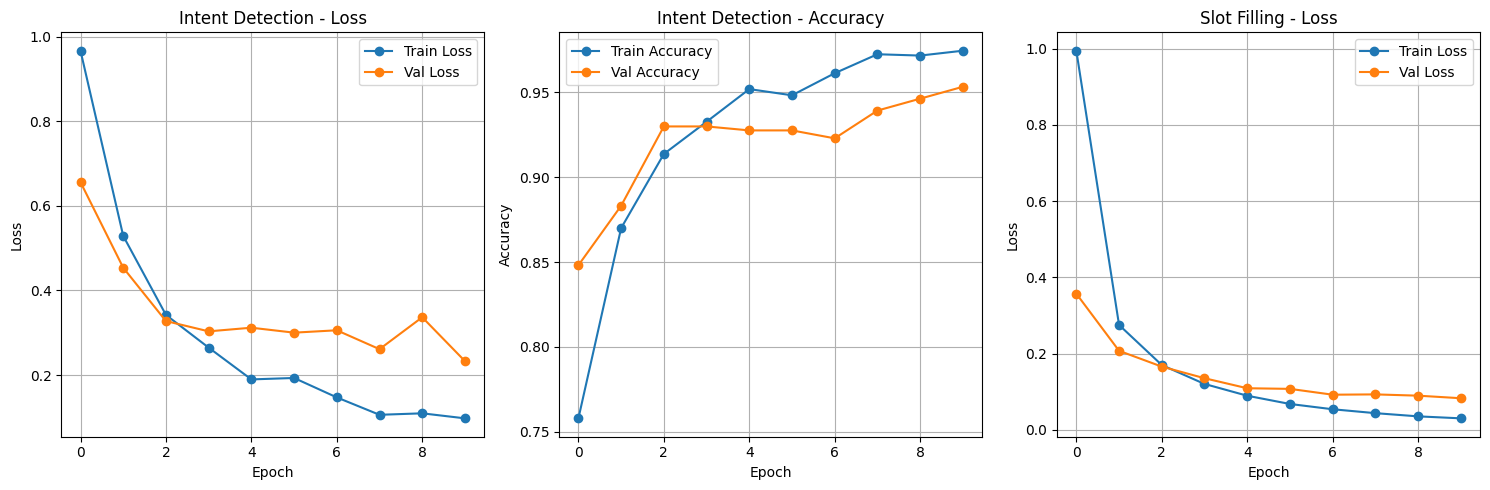

In [40]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(intent_train_losses, label='Train Loss', marker='o')
plt.plot(intent_val_losses, label='Val Loss', marker='o')
plt.title('Intent Detection - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(intent_train_accs, label='Train Accuracy', marker='o')
plt.plot(intent_val_accs, label='Val Accuracy', marker='o')
plt.title('Intent Detection - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(slot_train_losses, label='Train Loss', marker='o')
plt.plot(slot_val_losses, label='Val Loss', marker='o')
plt.title('Slot Filling - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [42]:
print("\n=== Final Test Results ===")
test_intent_loss, test_intent_acc = evaluate_intent(intent_model, test_loader, criterion_intent)
print(f"Test Intent Accuracy: {test_intent_acc * 100:.2f}%")

_, test_slot_f1, true_slots, pred_slots = evaluate_slot(slot_model, test_loader, criterion_slot)
print(f"Test Slot F1 Score (seqeval): {test_slot_f1:.4f}")
print("\nClassification Report:")
print(classification_report(true_slots, pred_slots))


=== Final Test Results ===
Test Intent Accuracy: 95.56%
Test Slot F1 Score (seqeval): 0.9364

Classification Report:
                            precision    recall  f1-score   support

             aircraft_code       0.31      0.71      0.43         7
              airline_code       0.95      0.95      0.95        22
              airline_name       0.98      0.98      0.98        91
              airport_code       1.00      0.25      0.40         4
              airport_name       0.29      0.25      0.27         8
 arrive_date.date_relative       0.00      0.00      0.00         1
      arrive_date.day_name       0.50      0.60      0.55        10
    arrive_date.day_number       0.67      0.86      0.75         7
    arrive_date.month_name       1.00      0.86      0.92         7
      arrive_time.end_time       0.67      0.67      0.67         3
    arrive_time.period_mod       0.00      0.00      0.00         1
 arrive_time.period_of_day       0.62      0.62      0.62        

c:\Users\Ali.M\AppData\Local\Programs\Python\Python38\lib\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


# 1-3

In [10]:
import torch
import torch.nn as nn

class JointBiLSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, 
                 num_intents=None, num_slots=None, dropout=0.5, padding_idx=0):
        super().__init__()
        
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=padding_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, bidirectional=True, batch_first=True)
        
        self.dropout = nn.Dropout(dropout)
        
        self.intent_head = nn.Linear(hidden_dim * 2, num_intents)  
        
        self.slot_head = nn.Linear(hidden_dim * 2, num_slots)
    
    def forward(self, x):
        emb = self.embedding(x)                    
        lstm_out, _ = self.lstm(emb)               
        lstm_out = self.dropout(lstm_out)
        
        intent_logits = self.intent_head(lstm_out[:, 0, :])   
        
        slot_logits = self.slot_head(lstm_out)               
        
        return intent_logits, slot_logits

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.metrics import accuracy_score
from seqeval.metrics import f1_score, classification_report
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

joint_model = JointBiLSTMModel(
    vocab_size=len(word_vocab),
    embed_dim=128,
    hidden_dim=128,
    num_intents=len(intent2id),
    num_slots=len(slot2id),
    dropout=0.5,
    padding_idx=word2id['<PAD>']
).to(device)

criterion_intent = nn.CrossEntropyLoss()
criterion_slot = nn.CrossEntropyLoss(ignore_index=-1) 

optimizer = optim.Adam(joint_model.parameters(), lr=0.001)

joint_train_losses = []
joint_val_losses = []
joint_train_intent_accs = []
joint_val_intent_accs = []
joint_val_slot_f1s = []

num_epochs = 10

print("Starting Joint BiLSTM Training...\n")

for epoch in range(num_epochs):
    joint_model.train()
    total_loss = 0.0
    intent_correct = 0
    intent_total = 0
    
    for sents, slots, intents in train_loader:
        sents = sents.to(device)
        slots = slots.to(device)
        intents = intents.to(device)
        
        optimizer.zero_grad()
        
        intent_logits, slot_logits = joint_model(sents)
        
    
        loss_intent = criterion_intent(intent_logits, intents)
        loss_slot = criterion_slot(slot_logits.view(-1, len(slot2id)), slots.view(-1))
        
    
        loss = loss_intent + loss_slot
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    
        preds_intent = torch.argmax(intent_logits, dim=1)
        intent_correct += (preds_intent == intents).sum().item()
        intent_total += intents.size(0)
    
    avg_train_loss = total_loss / len(train_loader)
    train_intent_acc = intent_correct / intent_total
    
    joint_train_losses.append(avg_train_loss)
    joint_train_intent_accs.append(train_intent_acc)
    

    joint_model.eval()
    val_loss = 0.0
    val_intent_correct = 0
    val_intent_total = 0
    val_pred_slots = []
    val_true_slots = []
    
    with torch.no_grad():
        for sents, slots, intents in val_loader:
            sents = sents.to(device)
            slots_np = slots.numpy()
            intents = intents.to(device)
            
            intent_logits, slot_logits = joint_model(sents)
            
            loss_intent = criterion_intent(intent_logits, intents)
            loss_slot = criterion_slot(slot_logits.view(-1, len(slot2id)), slots.view(-1).to(device))
            loss = loss_intent + loss_slot
            val_loss += loss.item()
            
        
            preds_intent = torch.argmax(intent_logits, dim=1)
            val_intent_correct += (preds_intent == intents).sum().item()
            val_intent_total += intents.size(0)
            
        
            preds_slot = torch.argmax(slot_logits, dim=-1).cpu().numpy()
            for p, s in zip(preds_slot, slots_np):
                mask = s != -1
                valid_len = mask.sum()
                val_pred_slots.append([id2slot[pp] for pp in p[:valid_len]])
                val_true_slots.append([id2slot[ss] for ss in s[:valid_len]])
    
    avg_val_loss = val_loss / len(val_loader)
    val_intent_acc = val_intent_correct / val_intent_total
    val_slot_f1 = f1_score(val_true_slots, val_pred_slots)
    
    joint_val_losses.append(avg_val_loss)
    joint_val_intent_accs.append(val_intent_acc)
    joint_val_slot_f1s.append(val_slot_f1)
    
    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"  Train Loss: {avg_train_loss:.4f} | Train Intent Acc: {train_intent_acc*100:.2f}%")
    print(f"  Val Loss: {avg_val_loss:.4f} | Val Intent Acc: {val_intent_acc*100:.2f}% | Val Slot F1: {val_slot_f1:.4f}")

Starting Joint BiLSTM Training...

Epoch 1/10
  Train Loss: 2.6329 | Train Intent Acc: 74.26%
  Val Loss: 1.3526 | Val Intent Acc: 79.44% | Val Slot F1: 0.6470
Epoch 2/10
  Train Loss: 0.9803 | Train Intent Acc: 86.82%
  Val Loss: 0.7172 | Val Intent Acc: 89.95% | Val Slot F1: 0.8308
Epoch 3/10
  Train Loss: 0.5543 | Train Intent Acc: 92.36%
  Val Loss: 0.5106 | Val Intent Acc: 92.29% | Val Slot F1: 0.8745
Epoch 4/10
  Train Loss: 0.3724 | Train Intent Acc: 94.80%
  Val Loss: 0.4081 | Val Intent Acc: 94.39% | Val Slot F1: 0.9060
Epoch 5/10
  Train Loss: 0.2525 | Train Intent Acc: 97.04%
  Val Loss: 0.3269 | Val Intent Acc: 94.86% | Val Slot F1: 0.9259
Epoch 6/10
  Train Loss: 0.1814 | Train Intent Acc: 98.10%
  Val Loss: 0.3222 | Val Intent Acc: 94.86% | Val Slot F1: 0.9310
Epoch 7/10
  Train Loss: 0.1347 | Train Intent Acc: 99.04%
  Val Loss: 0.2848 | Val Intent Acc: 94.86% | Val Slot F1: 0.9329
Epoch 8/10
  Train Loss: 0.0999 | Train Intent Acc: 99.40%
  Val Loss: 0.2611 | Val Intent

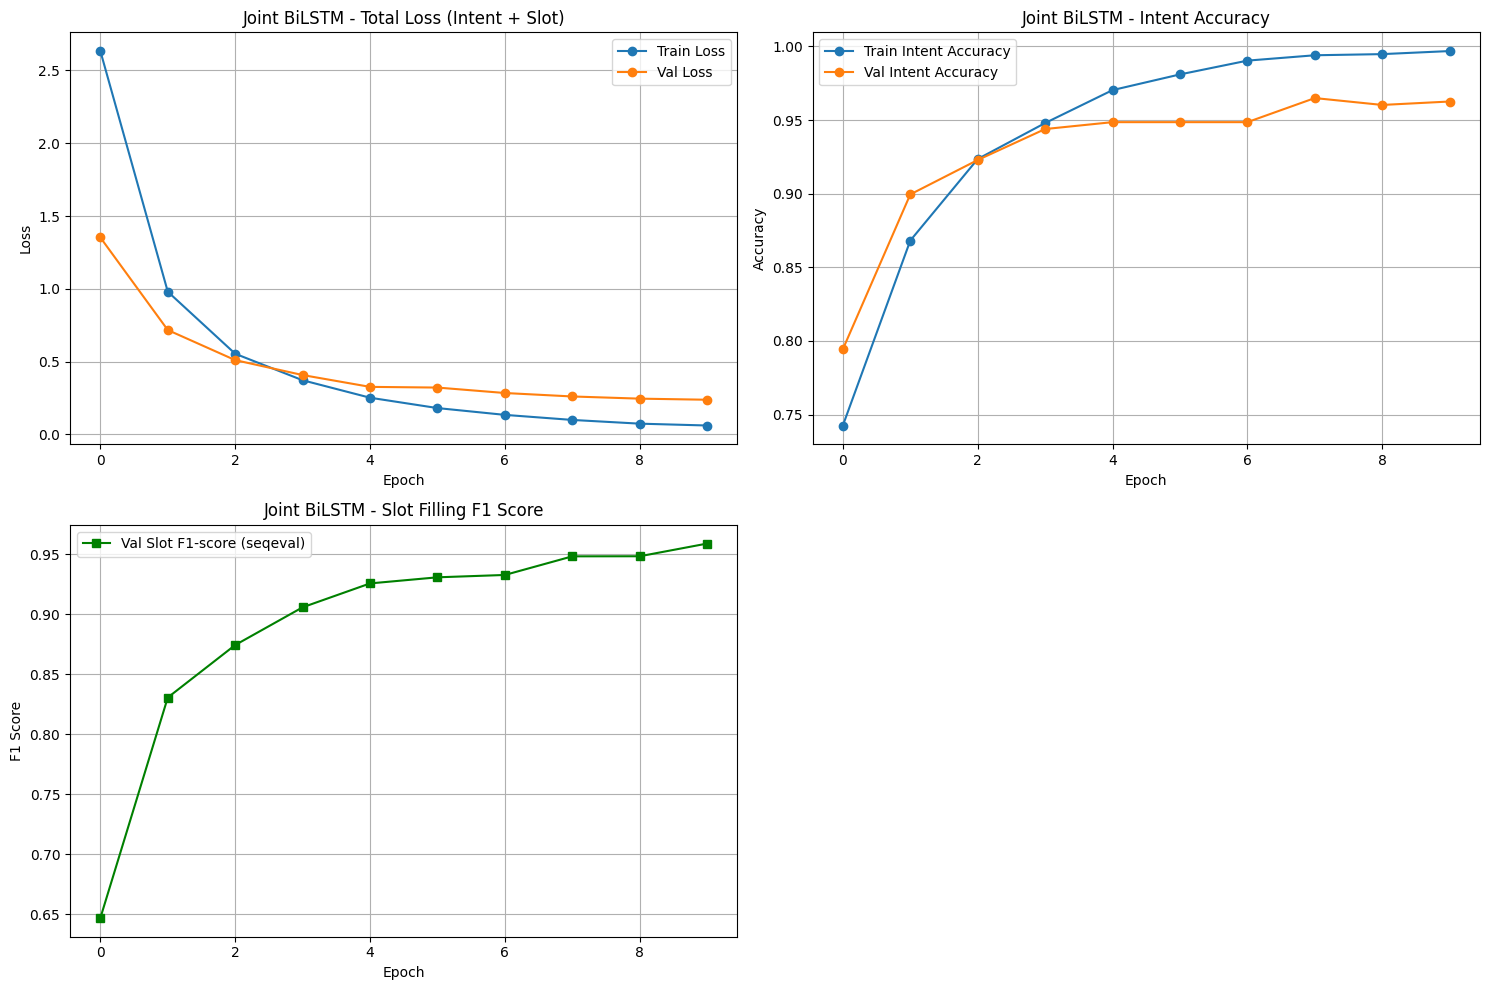

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.plot(joint_train_losses, label='Train Loss', marker='o')
plt.plot(joint_val_losses, label='Val Loss', marker='o')
plt.title('Joint BiLSTM - Total Loss (Intent + Slot)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(joint_train_intent_accs, label='Train Intent Accuracy', marker='o')
plt.plot(joint_val_intent_accs, label='Val Intent Accuracy', marker='o')
plt.title('Joint BiLSTM - Intent Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(joint_val_slot_f1s, label='Val Slot F1-score (seqeval)', marker='s', color='green')
plt.title('Joint BiLSTM - Slot Filling F1 Score')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [14]:
joint_model.eval()
test_intent_correct = 0
test_intent_total = 0
test_pred_slots = []
test_true_slots = []

with torch.no_grad():
    for sents, slots, intents in test_loader:
        sents = sents.to(device)
        intents = intents.to(device)
        slots_np = slots.numpy()
        
        intent_logits, slot_logits = joint_model(sents)
        
        
        preds_intent = torch.argmax(intent_logits, dim=1)
        test_intent_correct += (preds_intent == intents).sum().item()
        test_intent_total += intents.size(0)
        
        
        preds_slot = torch.argmax(slot_logits, dim=-1).cpu().numpy()
        for p, s in zip(preds_slot, slots_np):
            mask = s != -1
            valid_len = mask.sum()
            test_pred_slots.append([id2slot[pp] for pp in p[:valid_len]])
            test_true_slots.append([id2slot[ss] for ss in s[:valid_len]])

test_intent_acc = test_intent_correct / test_intent_total
test_slot_f1 = f1_score(test_true_slots, test_pred_slots)
report = classification_report(test_true_slots, test_pred_slots)

print("=== Final Test Results (Joint BiLSTM) ===")
print(f"Test Intent Accuracy: {test_intent_acc * 100:.2f}%")
print(f"Test Slot F1 Score (seqeval): {test_slot_f1:.4f}")
print("\nClassification Report (Slots):")
print(report)

=== Final Test Results (Joint BiLSTM) ===
Test Intent Accuracy: 97.95%
Test Slot F1 Score (seqeval): 0.9422

Classification Report (Slots):
                            precision    recall  f1-score   support

             aircraft_code       1.00      0.86      0.92         7
              airline_code       1.00      0.95      0.98        22
              airline_name       0.97      0.97      0.97        91
              airport_code       0.00      0.00      0.00         4
              airport_name       0.45      0.62      0.53         8
 arrive_date.date_relative       0.00      0.00      0.00         1
      arrive_date.day_name       0.71      0.50      0.59        10
    arrive_date.day_number       0.86      0.86      0.86         7
    arrive_date.month_name       1.00      0.86      0.92         7
      arrive_time.end_time       1.00      1.00      1.00         3
    arrive_time.period_mod       0.00      0.00      0.00         1
 arrive_time.period_of_day       0.67      

c:\Users\Ali.M\AppData\Local\Programs\Python\Python38\lib\site-packages\seqeval\metrics\v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


# 1-4


In [6]:

if '<BOS>' not in slot_vocab:
    slot_vocab = ['<BOS>', '<EOS>'] + slot_vocab 
slot2id = {s: i for i, s in enumerate(slot_vocab)}
id2slot = {i: s for s, i in slot2id.items()}
num_slots = len(slot_vocab)
print(f"Updated slot vocab size: {num_slots} (including <BOS> and <EOS>)")
print(slot2id)

class ATISDatasetJointSeq2Seq(Dataset):
    def __init__(self, df, word2id, slot2id, intent2id):
        self.sentences = [tokenize(s) for s in df['tokens']]
        self.raw_slots = [tokenize(s) for s in df['slots']]
        self.intents = df['intent'].tolist()
        
        self.word2id = word2id
        self.slot2id = slot2id
        self.intent2id = intent2id
    
    def __len__(self):
        return len(self.sentences)
    
    def __getitem__(self, idx):
        sent = self.sentences[idx]
        slot = self.raw_slots[idx]
        intent = self.intents[idx]
        
        sent_id = [self.word2id.get(w, self.word2id['<UNK>']) for w in sent]
        
        slot_id = [self.slot2id['<BOS>']] + [self.slot2id[s] for s in slot] + [self.slot2id['<EOS>']]
        
        intent_id = self.intent2id[intent]
        
        return torch.tensor(sent_id), torch.tensor(slot_id), torch.tensor(intent_id)

Updated slot vocab size: 103 (including <BOS> and <EOS>)
{'<BOS>': 0, '<EOS>': 1, 'B-aircraft_code': 2, 'B-airline_code': 3, 'B-airline_name': 4, 'B-airport_code': 5, 'B-airport_name': 6, 'B-arrive_date.date_relative': 7, 'B-arrive_date.day_name': 8, 'B-arrive_date.day_number': 9, 'B-arrive_date.month_name': 10, 'B-arrive_time.end_time': 11, 'B-arrive_time.period_mod': 12, 'B-arrive_time.period_of_day': 13, 'B-arrive_time.start_time': 14, 'B-arrive_time.time': 15, 'B-arrive_time.time_relative': 16, 'B-city_name': 17, 'B-class_type': 18, 'B-connect': 19, 'B-cost_relative': 20, 'B-day_name': 21, 'B-depart_date.date_relative': 22, 'B-depart_date.day_name': 23, 'B-depart_date.day_number': 24, 'B-depart_date.month_name': 25, 'B-depart_date.today_relative': 26, 'B-depart_date.year': 27, 'B-depart_time.end_time': 28, 'B-depart_time.period_mod': 29, 'B-depart_time.period_of_day': 30, 'B-depart_time.start_time': 31, 'B-depart_time.time': 32, 'B-depart_time.time_relative': 33, 'B-economy': 34, '

In [7]:
BATCH_SIZE = 32
def collate_fn(batch):
    sents, slots, intents = zip(*batch)
    
    padded_sents = pad_sequence(sents, batch_first=True, padding_value=word2id['<PAD>'])
    
    padded_slots = pad_sequence(slots, batch_first=True, padding_value=slot2id['O'])
    
    intents = torch.stack(intents)
    
    return padded_sents, padded_slots, intents

train_dataset = ATISDatasetJointSeq2Seq(train_df, word2id, slot2id, intent2id)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

val_dataset = ATISDatasetJointSeq2Seq(val_df, word2id, slot2id, intent2id)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

test_dataset = ATISDatasetJointSeq2Seq(test_df, word2id, slot2id, intent2id)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)

In [8]:
import torch
import torch.nn as nn
print(slot2id.keys())
iii = slot2id['O']

class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=128, padding_idx=-1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=padding_idx)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True) 
    
    def forward(self, x):
        emb = self.embedding(x) 
        _, (hn, cn) = self.lstm(emb) 
        return hn.squeeze(0), cn.squeeze(0) 

class Decoder(nn.Module):
    def __init__(self, slot_vocab_size, embed_dim=64, hidden_dim=256, num_intents=None, num_slots=None, dropout=0.5):
        super().__init__()
        self.embedding = nn.Embedding(slot_vocab_size + 1, embed_dim, padding_idx= -1)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.intent_head = nn.Linear(hidden_dim, num_intents)
        self.slot_head = nn.Linear(hidden_dim, num_slots)
        self.hidden_projection = nn.Linear(128, hidden_dim)
    
    def forward(self, slot_inputs, init_h, init_c):
        h0 = self.hidden_projection(init_h) 
        c0 = self.hidden_projection(init_c)
        emb = self.embedding(slot_inputs) 
        lstm_out, (hn, _) = self.lstm(emb, (h0.unsqueeze(0), c0.unsqueeze(0))) 
        lstm_out = self.dropout(lstm_out)
        
        intent_logits = self.intent_head(hn.squeeze(0)) 
        
        slot_logits = self.slot_head(lstm_out)
        
        return intent_logits, slot_logits

dict_keys(['<BOS>', '<EOS>', 'B-aircraft_code', 'B-airline_code', 'B-airline_name', 'B-airport_code', 'B-airport_name', 'B-arrive_date.date_relative', 'B-arrive_date.day_name', 'B-arrive_date.day_number', 'B-arrive_date.month_name', 'B-arrive_time.end_time', 'B-arrive_time.period_mod', 'B-arrive_time.period_of_day', 'B-arrive_time.start_time', 'B-arrive_time.time', 'B-arrive_time.time_relative', 'B-city_name', 'B-class_type', 'B-connect', 'B-cost_relative', 'B-day_name', 'B-depart_date.date_relative', 'B-depart_date.day_name', 'B-depart_date.day_number', 'B-depart_date.month_name', 'B-depart_date.today_relative', 'B-depart_date.year', 'B-depart_time.end_time', 'B-depart_time.period_mod', 'B-depart_time.period_of_day', 'B-depart_time.start_time', 'B-depart_time.time', 'B-depart_time.time_relative', 'B-economy', 'B-fare_amount', 'B-fare_basis_code', 'B-flight_days', 'B-flight_mod', 'B-flight_number', 'B-flight_stop', 'B-flight_time', 'B-fromloc.airport_code', 'B-fromloc.airport_name', 'B

In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.metrics import accuracy_score
from seqeval.metrics import f1_score, classification_report
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

encoder = Encoder(vocab_size=len(word_vocab), embed_dim=128, hidden_dim=128).to(device)
decoder = Decoder(
    slot_vocab_size=len(slot_vocab),
    embed_dim=64,
    hidden_dim=256,
    num_intents=len(intent2id),
    num_slots=len(slot2id),
    dropout=0.5
).to(device)

criterion_intent = nn.CrossEntropyLoss()
criterion_slot = nn.CrossEntropyLoss(ignore_index=-1)

optimizer = optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), lr=0.001)

encdec_train_losses = []
encdec_val_losses = []
encdec_train_intent_accs = []
encdec_val_intent_accs = []
encdec_val_slot_f1s = []

num_epochs = 10 

print("Starting Encoder-Decoder Joint Training...\n")

for epoch in range(num_epochs):
    encoder.train()
    decoder.train()
    total_loss = 0.0
    intent_correct = 0
    intent_total = 0
    
    for sents, slots_full, intents in train_loader:
        sents = sents.to(device)
        slots_full = slots_full.to(device)
        intents = intents.to(device)
        
        optimizer.zero_grad()
        
        h0, c0 = encoder(sents)
        # print(slots_full)
        slot_inputs = slots_full[:, :-1]   
        slot_targets = slots_full[:, 1:]   
        
        
        intent_logits, slot_logits = decoder(slot_inputs, h0, c0)
        
        
        loss_intent = criterion_intent(intent_logits, intents)
        # loss_slot = criterion_slot(slot_logits.view(-1, len(slot2id)), slot_targets.view(-1))
        # loss_slot = criterion_slot(slot_logits.reshape(-1, len(slot2id)), slot_targets.view(-1))
        loss_slot = criterion_slot(
            slot_logits.contiguous().view(-1, len(slot2id)),
            slot_targets.contiguous().view(-1)
        )
        loss = loss_intent + loss_slot
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
        preds_intent = torch.argmax(intent_logits, dim=1)
        intent_correct += (preds_intent == intents).sum().item()
        intent_total += intents.size(0)
    
    avg_train_loss = total_loss / len(train_loader)
    train_intent_acc = intent_correct / intent_total
    
    encdec_train_losses.append(avg_train_loss)
    encdec_train_intent_accs.append(train_intent_acc)
    
    
    
    # Val
    
    encoder.eval()
    decoder.eval()
    val_loss_total = 0.0
    val_intent_correct = 0
    val_intent_total = 0
    val_true_slots = []
    val_pred_slots = []
    
    with torch.no_grad():
        for sents, slots_full, intents in val_loader:
            sents = sents.to(device)
            slots_full = slots_full.to(device)
            intents = intents.to(device)
            
            h0, c0 = encoder(sents)
            slot_inputs = slots_full[:, :-1]
            slot_targets = slots_full[:, 1:]
            
            intent_logits, slot_logits = decoder(slot_inputs, h0, c0)
            
            loss_intent = criterion_intent(intent_logits, intents)
            # loss_slot = criterion_slot(slot_logits.view(-1, len(slot2id)), slot_targets.view(-1))
            loss_slot = criterion_slot(
                slot_logits.contiguous().view(-1, len(slot2id)),
                slot_targets.contiguous().view(-1)
            )
            val_loss_total += (loss_intent + loss_slot).item()
            
            
            preds_intent = torch.argmax(intent_logits, dim=1)
            val_intent_correct += (preds_intent == intents).sum().item()
            val_intent_total += intents.size(0)
            
            
            val_true_slots = []
            val_pred_slots = []

            preds_slot = torch.argmax(slot_logits, dim=-1).cpu().numpy()
            targets_slot = slot_targets.cpu().numpy()

            for i in range(preds_slot.shape[0]):
                pred = preds_slot[i]
                target = targets_slot[i]
                
                length = 0
                for t in target:
                    if t == slot2id['<EOS>']:
                        break
                    length += 1
                
                true_seq = [id2slot[target[j]] for j in range(length)]
                pred_seq = [id2slot[pred[j]] for j in range(length)]
                
                val_true_slots.append(true_seq)
                val_pred_slots.append(pred_seq)
    
    avg_val_loss = val_loss_total / len(val_loader)
    val_intent_acc = val_intent_correct / val_intent_total
    val_slot_f1 = f1_score(val_true_slots, val_pred_slots)
    
    encdec_val_losses.append(avg_val_loss)
    encdec_val_intent_accs.append(val_intent_acc)
    encdec_val_slot_f1s.append(val_slot_f1)
    
    print(f"Epoch {epoch//2+1}/{10}")
    print(f"  Train → Loss: {avg_train_loss:.4f} | Intent Acc: {train_intent_acc*100:.2f}%")
    print(f"  Val   → Loss: {avg_val_loss:.4f} | Intent Acc: {val_intent_acc*100:.2f}% | Slot F1: {val_slot_f1:.4f}\n")

Starting Encoder-Decoder Joint Training...

Epoch 1/10
  Train → Loss: 2.4592 | Intent Acc: 73.37%
  Val   → Loss: 1.8926 | Intent Acc: 75.23% | Slot F1: 0.0000

Epoch 2/10
  Train → Loss: 1.6433 | Intent Acc: 74.44%
  Val   → Loss: 1.4772 | Intent Acc: 76.64% | Slot F1: 0.3836

Epoch 3/10
  Train → Loss: 1.3468 | Intent Acc: 77.59%
  Val   → Loss: 1.3407 | Intent Acc: 78.50% | Slot F1: 0.3288

Epoch 4/10
  Train → Loss: 1.0266 | Intent Acc: 84.97%
  Val   → Loss: 1.0508 | Intent Acc: 84.58% | Slot F1: 0.3099

Epoch 5/10
  Train → Loss: 0.8850 | Intent Acc: 88.69%
  Val   → Loss: 0.9902 | Intent Acc: 83.88% | Slot F1: 0.3509

Epoch 6/10
  Train → Loss: 0.7843 | Intent Acc: 90.64%
  Val   → Loss: 0.8461 | Intent Acc: 87.15% | Slot F1: 0.3881

Epoch 7/10
  Train → Loss: 0.6924 | Intent Acc: 92.75%
  Val   → Loss: 0.8238 | Intent Acc: 88.79% | Slot F1: 0.4658

Epoch 8/10
  Train → Loss: 0.6394 | Intent Acc: 93.42%
  Val   → Loss: 0.8337 | Intent Acc: 88.55% | Slot F1: 0.4250

Epoch 9/10
 

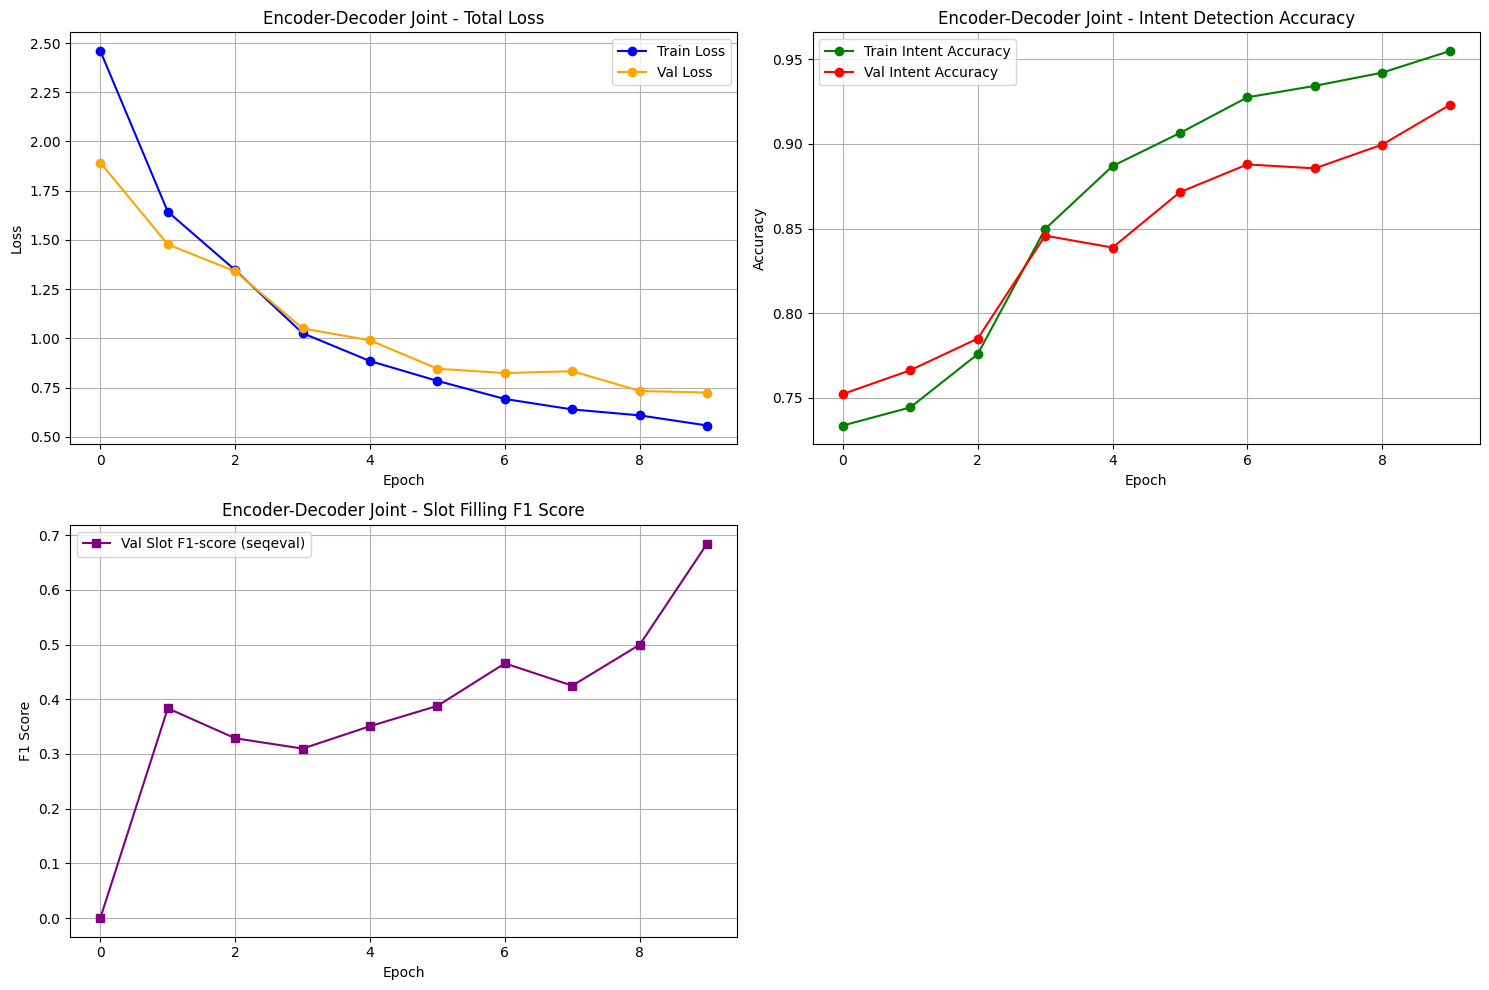

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.plot(encdec_train_losses, label='Train Loss', marker='o', color='blue')
plt.plot(encdec_val_losses, label='Val Loss', marker='o', color='orange')
plt.title('Encoder-Decoder Joint - Total Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(encdec_train_intent_accs, label='Train Intent Accuracy', marker='o', color='green')
plt.plot(encdec_val_intent_accs, label='Val Intent Accuracy', marker='o', color='red')
plt.title('Encoder-Decoder Joint - Intent Detection Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(encdec_val_slot_f1s, label='Val Slot F1-score (seqeval)', marker='s', color='purple')
plt.title('Encoder-Decoder Joint - Slot Filling F1 Score')
plt.xlabel('Epoch')
plt.ylabel('F1 Score')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [17]:
encoder.eval()
decoder.eval()

test_intent_correct = 0
test_intent_total = 0
test_true_slots = []
test_pred_slots = []

with torch.no_grad():
    for sents, slots_full, intents in test_loader:
        sents = sents.to(device)
        slots_full = slots_full.to(device)
        intents = intents.to(device)
        
        h0_enc, c0_enc = encoder(sents)
        slot_inputs = slots_full[:, :-1]
        
        intent_logits, slot_logits = decoder(slot_inputs, h0_enc, c0_enc)
        
        preds_intent = torch.argmax(intent_logits, dim=1)
        test_intent_correct += (preds_intent == intents).sum().item()
        test_intent_total += intents.size(0)
        
        preds_slot = torch.argmax(slot_logits, dim=-1).cpu().numpy()
        targets_slot = slots_full[:, 1:].cpu().numpy()             
        
        for i in range(preds_slot.shape[0]):
            pred = preds_slot[i]
            target = targets_slot[i]
            
            length = 0
            for t in target:
                if t == slot2id['<EOS>']:
                    break
                length += 1
            
            true_seq = [id2slot[target[j]] for j in range(length)]
            pred_seq = [id2slot[pred[j]] for j in range(length)]
            
            test_true_slots.append(true_seq)
            test_pred_slots.append(pred_seq)

test_intent_acc = test_intent_correct / test_intent_total
test_slot_f1 = f1_score(test_true_slots, test_pred_slots)
test_report = classification_report(test_true_slots, test_pred_slots)

print("\n" + "="*60)
print("="*60)
print(f"Intent Detection Accuracy: {test_intent_acc * 100:.2f}%")


print(f"\nSlot Filling F1-score (seqeval): {test_slot_f1:.4f}")

print("\nClassification Report (Slot Filling):")
print(test_report)
print("="*60)


Intent Detection Accuracy: 93.00%

Slot Filling F1-score (seqeval): 0.4694

Classification Report (Slot Filling):
                            precision    recall  f1-score   support

                      EOS>       0.00      0.00      0.00         0
             aircraft_code       0.00      0.00      0.00         7
              airline_code       0.00      0.00      0.00        22
              airline_name       0.00      0.00      0.00        91
              airport_code       0.00      0.00      0.00         4
              airport_name       0.00      0.00      0.00         8
 arrive_date.date_relative       0.00      0.00      0.00         1
      arrive_date.day_name       0.00      0.00      0.00        10
    arrive_date.day_number       0.86      0.86      0.86         7
    arrive_date.month_name       0.00      0.00      0.00         7
      arrive_time.end_time       0.33      0.33      0.33         3
    arrive_time.period_mod       0.00      0.00      0.00         1


In [18]:
import random
def greedy_decode(encoder, decoder, word_ids, device, max_len=50):
    encoder.eval()
    decoder.eval()
    
    with torch.no_grad():
        word_ids = word_ids.unsqueeze(0).to(device)
        h0, c0 = encoder(word_ids)
        

        decoder_input = torch.tensor([[slot2id['<BOS>']]], device=device)
        predicted_slots = []
        
        for _ in range(max_len):
            intent_logits, slot_logits = decoder(decoder_input, h0, c0)
            
    
            next_token_logits = slot_logits[:, -1, :]
            next_token_id = torch.argmax(next_token_logits, dim=-1)
            
            next_id = next_token_id.item()
            predicted_slots.append(next_id)
            
    
            if next_id == slot2id['<EOS>']:
                break
            
    
            decoder_input = torch.cat([decoder_input, next_token_id.unsqueeze(1)], dim=1)
    
    pred_slot_names = []
    for pid in predicted_slots:
        if pid == slot2id['<EOS>']:
            break
        if pid != slot2id['<BOS>']:
            pred_slot_names.append(id2slot[pid])
    
    return pred_slot_names
test_indices = random.sample(range(len(test_dataset)), 5)

print("="*80)
for idx in test_indices:
    sent_ids, slots_full, intent_id = test_dataset[idx]
    
    original_sentence = ' '.join([id2word[wid.item()] for wid in sent_ids if wid != word2id['<PAD>']])
    
    true_slot_ids = slots_full[1:-1].tolist()
    true_slot_names = [id2slot[sid] for sid in true_slot_ids if sid != slot2id['<EOS>']]
    
    predicted_slot_names = greedy_decode(encoder, decoder, sent_ids, device)
    
    print(f"\nExample {test_indices.index(idx)+1}:")
    print(f"Sentence: {original_sentence}")
    print(f"True Intent: {intent_vocab[intent_id]}")
    print(f"True Slots:     {true_slot_names}")
    print(f"Predicted Slots (Greedy): {predicted_slot_names}")
    print("-" * 70)


Example 1:
Sentence: BOS now show me all the flights from st. louis to burbank EOS
True Intent: atis_flight
True Slots:     ['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-city_name', 'I-city_name', 'O', 'B-toloc.city_name', 'O']
Predicted Slots (Greedy): ['O', 'O', 'O', 'O', 'O', 'O', 'O', 'O', 'B-fromloc.city_name', 'O', 'B-toloc.city_name', 'O']
----------------------------------------------------------------------

Example 2:
Sentence: BOS list flights from seattle to salt lake city on delta <UNK> EOS
True Intent: atis_flight
True Slots:     ['O', 'O', 'O', 'O', 'B-fromloc.city_name', 'O', 'B-toloc.city_name', 'I-toloc.city_name', 'I-toloc.city_name', 'O', 'B-airline_name', 'B-aircraft_code', 'O']
Predicted Slots (Greedy): ['O', 'O', 'O', 'O', 'B-fromloc.city_name', 'O', 'B-toloc.city_name', 'O', 'O', 'O', 'O', 'O', 'O']
----------------------------------------------------------------------

Example 3:
Sentence: BOS i'd like a list of the flights from oakland to dallas fort worth on s